# Missing data EDA: mansion dataset

The goal is to establish **how much is missing, when it is missing, which features fail together, and how long gaps last**, before choosing a treatment. Source: the supplied `dataset_mansion.csv`. No values are imputed or removed here.

Run this notebook with the CSV in the same directory, or change `DATA_PATH` below. Outputs are included. Timestamps are used exactly as supplied; the CSV does not specify their timezone.

## 1. Validate the timeline and parsing

Missing timestamps and missing cells are different problems. Check the original timeline before reindexing. Parsing raises an error for unexpected consumption values rather than silently converting them into NaN. Pandas' default missing-value tokens are used; check the source documentation for additional sentinel codes. Zero is not treated as missing.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path('dataset_mansion.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('upload/dataset_mansion.csv')

raw = pd.read_csv(DATA_PATH, index_col=0)
raw['Consumption'] = pd.to_numeric(
    raw['Consumption'].astype('string').str.replace(',', '.', regex=False),
    errors='raise'
)
raw['MTime'] = pd.to_datetime(raw['MTime'], errors='raise')
assert raw['MTime'].notna().all(), 'Investigate missing timestamps first.'
assert not raw['MTime'].duplicated().any(), 'Resolve duplicate timestamps first.'
df = raw.set_index('MTime').sort_index()
assert (df.index == df.index.floor('h')).all(), 'Investigate off-hour timestamps.'
expected = pd.date_range(df.index.min(), df.index.max(), freq='h')
missing_timestamps = expected.difference(df.index)
aligned = df.reindex(expected)
aligned.index.name = 'MTime'
missing = aligned.isna()
print(f'Original rows: {len(df):,}; expected hourly rows: {len(expected):,}')
print(f'Period: {df.index.min()} to {df.index.max()}')
print(f'Absent timestamps: {len(missing_timestamps):,}')
print(f'Columns: {len(aligned.columns)}')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

Original rows: 56,231; expected hourly rows: 56,231
Period: 2015-12-31 22:00:00 to 2022-05-31 20:00:00
Absent timestamps: 0
Columns: 16


**Result:** 56,231 unique, consecutive hourly observations from 2015-12-31 22:00 to 2022-05-31 20:00. There are **no missing timestamps**. In this file, hourly alignment introduces no additional missing cells.

## 2. Quantify missingness by feature

Use counts for exact reporting and percentages for comparison. Include complete features in the table. Use two chart panels because the 57.69% missing weather-rank column otherwise hides differences below 1.32%. Both axes start at zero, with explicitly different scales.

,Missing hours,Missing (%),Observed hours
PresentWeather(rank),32441,57.692,23790
MaximumWindSpeed(m/s),741,1.318,55490
MinimumWindSpeed(m/s),741,1.318,55490
WindSpeed(m/s),618,1.099,55613
WindDirection(deg),501,0.891,55730
MaximumPrecipitationIntensity(mm/h),321,0.571,55910
PrecipitationAmount(mm),303,0.539,55928
RelativeHumidity(%),289,0.514,55942
AirPressure(hPa),210,0.373,56021
AirTemperature(degC),208,0.370,56023


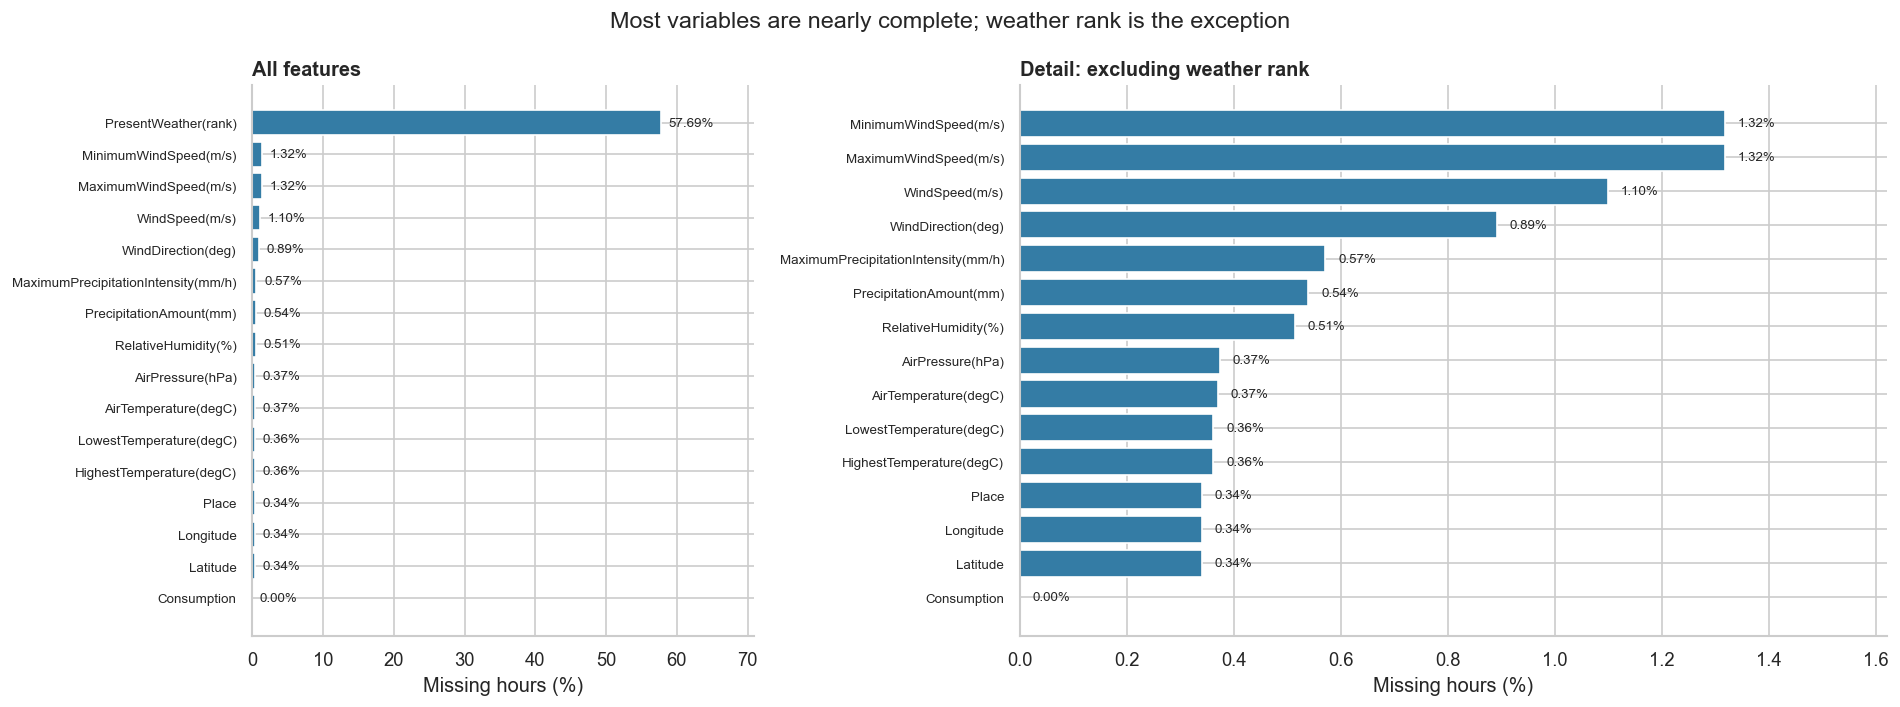

In [2]:
summary = pd.DataFrame({
    'Missing hours': missing.sum(),
    'Missing (%)': missing.mean().mul(100),
    'Observed hours': aligned.notna().sum()
}).sort_values('Missing hours', ascending=False)
display(summary.round(3))

rank_col = 'PresentWeather(rank)'
other_cols = [c for c in aligned.columns if c != rank_col]
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.1, 1.9]})
for ax, table, title in [
    (axes[0], summary, 'All features'),
    (axes[1], summary.drop(index=rank_col), 'Detail: excluding weather rank')
]:
    values = table['Missing (%)'].sort_values()
    ax.barh(values.index, values.values, color='#347ca5')
    ax.set_xlabel('Missing hours (%)')
    ax.set_title(title, loc='left', weight='bold')
    ax.set_xlim(0, max(values.max() * 1.23, .1))
    for i, value in enumerate(values):
        ax.text(value + ax.get_xlim()[1] * .015, i, f'{value:.2f}%', va='center', fontsize=8)
    ax.tick_params(axis='y', labelsize=8)
fig.suptitle('Most variables are nearly complete; weather rank is the exception', fontsize=14)
fig.tight_layout()
plt.show()

## 3. Show when data is missing

Aggregate the Boolean missing-value mask to a monthly **percentage of available hourly slots**. This measures frequency of missingness, not average weather values. Each month gets a visible column. Separate the weather-rank panel to retain detail in the other features. A monthly chart cannot reveal every individual outage; inspect specific windows next. The first and last months are partial months.

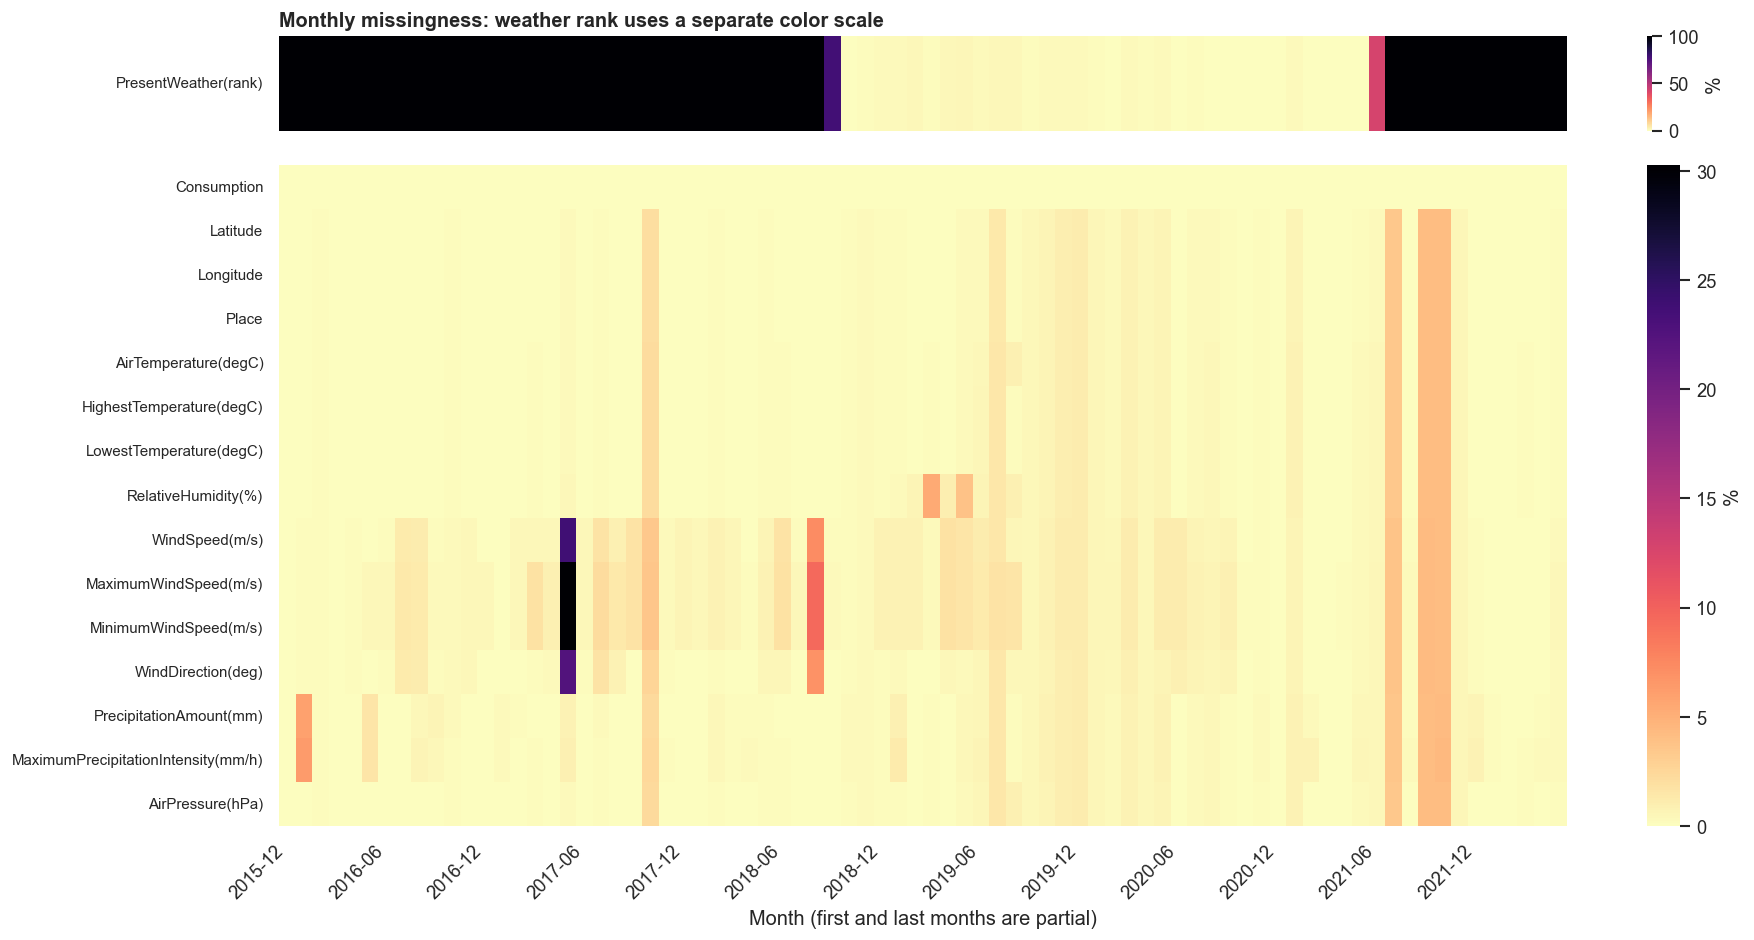

In [3]:
monthly = missing.resample('MS').mean().mul(100)
fig, axes = plt.subplots(2, 1, figsize=(16, 8), gridspec_kw={'height_ratios': [1, 7]})
for ax, cols, maximum in [(axes[0], [rank_col], 100), (axes[1], other_cols, monthly[other_cols].to_numpy().max())]:
    sns.heatmap(monthly[cols].T, ax=ax, cmap='magma_r', vmin=0,
                vmax=max(maximum, 1), xticklabels=False, yticklabels=True,
                cbar_kws={'label': '%'})
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='y', labelsize=9, rotation=0)
positions = np.arange(0, len(monthly), 6)
axes[1].set_xticks(positions + .5)
axes[1].set_xticklabels(monthly.index[positions].strftime('%Y-%m'), rotation=45, ha='right')
axes[1].set_xlabel('Month (first and last months are partial)')
axes[0].set_title('Monthly missingness: weather rank uses a separate color scale', loc='left', weight='bold')
fig.tight_layout()
plt.show()

**Finding:** Weather rank is missing throughout the first **23,940 hours**, ending 2018-09-24 09:00, and the final **8,342 hours**, starting 2021-06-18 07:00. These blocks alone account for 32,282 of its 32,441 missing values. This is strong temporal structure. The chart does not identify the collection or reporting cause.

## 4. Measure consecutive gap lengths

A 20-hour outage has different consequences from 20 isolated missing hours. Report the number of missing runs, median run length, maximum run length, and the dates of the longest run. Lengths below count missing hourly observations; a single missing observation is a one-hour gap.

,Missing runs,Median gap (h),Longest gap (h),Longest gap starts,Longest gap ends
Feature,,,,,
PresentWeather(rank),144,1.0,23940,2015-12-31 22:00:00,2018-09-24 09:00:00
MaximumWindSpeed(m/s),389,1.0,80,2017-05-13 10:00:00,2017-05-16 17:00:00
MinimumWindSpeed(m/s),389,1.0,80,2017-05-13 10:00:00,2017-05-16 17:00:00
WindSpeed(m/s),363,1.0,58,2017-05-14 06:00:00,2017-05-16 15:00:00
WindDirection(deg),251,1.0,58,2017-05-14 06:00:00,2017-05-16 15:00:00
Latitude,151,1.0,20,2021-07-18 10:00:00,2021-07-19 05:00:00
Longitude,151,1.0,20,2021-07-18 10:00:00,2021-07-19 05:00:00
Place,151,1.0,20,2021-07-18 10:00:00,2021-07-19 05:00:00
AirTemperature(degC),156,1.0,20,2021-07-18 10:00:00,2021-07-19 05:00:00


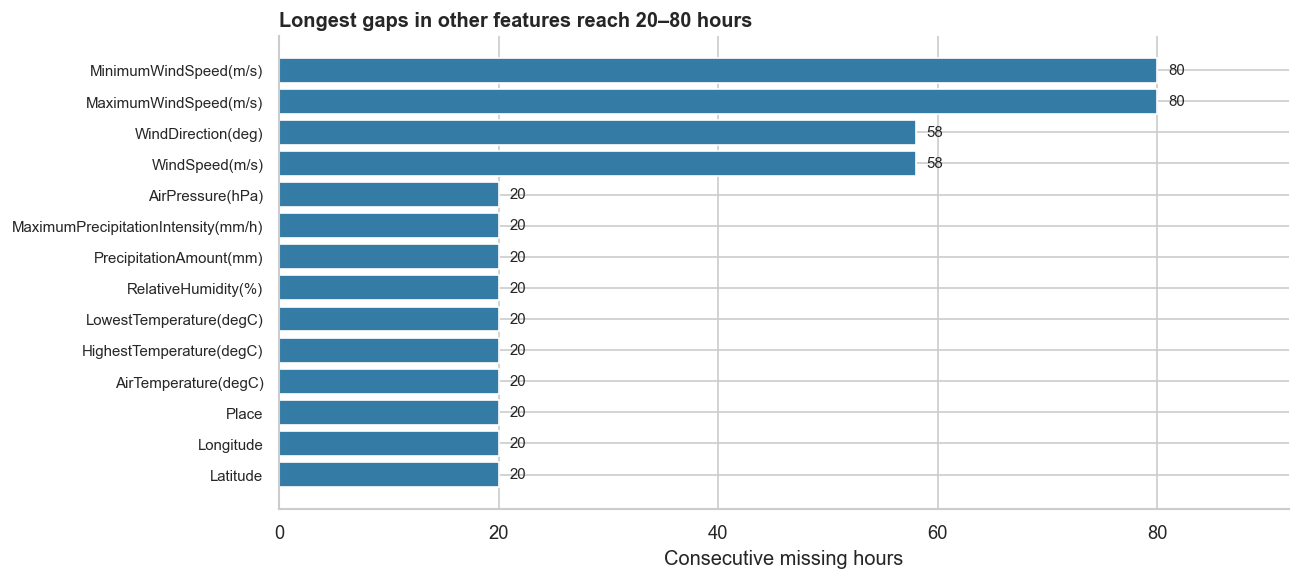

In [4]:
records = []
gap_records = []
for col in aligned.columns:
    s = missing[col]
    groups = s.ne(s.shift()).cumsum()
    for _, block in s[s].groupby(groups[s]):
        gap_records.append({'Feature': col, 'Start': block.index[0],
                            'End': block.index[-1], 'Hours': len(block)})
gaps = pd.DataFrame(gap_records)
for col, group in gaps.groupby('Feature', sort=False):
    longest = group.loc[group['Hours'].idxmax()]
    records.append({'Feature': col, 'Missing runs': len(group),
                    'Median gap (h)': group['Hours'].median(),
                    'Longest gap (h)': group['Hours'].max(),
                    'Longest gap starts': longest['Start'],
                    'Longest gap ends': longest['End']})
gap_summary = pd.DataFrame(records).set_index('Feature').sort_values('Longest gap (h)', ascending=False)
display(gap_summary)
fig, ax = plt.subplots(figsize=(11, 5))
values = gap_summary.drop(index=rank_col)['Longest gap (h)'].sort_values()
ax.barh(values.index, values, color='#347ca5')
for i, val in enumerate(values):
    ax.text(val + 1, i, str(val), va='center', fontsize=9)
ax.set_xlim(0, values.max() * 1.15)
ax.set_xlabel('Consecutive missing hours')
ax.set_title('Longest gaps in other features reach 20–80 hours', loc='left', weight='bold')
ax.tick_params(axis='y', labelsize=9)
fig.tight_layout()
plt.show()

## 5. Investigate features that go missing together

An exact missingness-pattern frequency table is easier to interpret here than a dense correlation heatmap. It counts rows once, even when several features are missing. Matching masks demonstrate co-occurrence; they do not prove a shared technical cause.

,Hours,Hours (%)
Missing features,,
PresentWeather(rank),31628,56.247
Complete,23654,42.066
"WindSpeed(m/s), MaximumWindSpeed(m/s), MinimumWindSpeed(m/s), WindDirection(deg), PresentWeather(rank)",282,0.502
"Latitude, Longitude, Place, AirTemperature(degC), HighestTemperature(degC), LowestTemperature(degC), RelativeHumidity(%), WindSpeed(m/s), MaximumWindSpeed(m/s), MinimumWindSpeed(m/s), WindDirection(deg), PrecipitationAmount(mm), MaximumPrecipitationIntensity(mm/h), AirPressure(hPa), PresentWeather(rank)",191,0.340
"WindSpeed(m/s), MaximumWindSpeed(m/s), MinimumWindSpeed(m/s), PresentWeather(rank)",117,0.208
"MaximumWindSpeed(m/s), MinimumWindSpeed(m/s), PresentWeather(rank)",106,0.189
"PrecipitationAmount(mm), MaximumPrecipitationIntensity(mm/h), PresentWeather(rank)",80,0.142
RelativeHumidity(%),78,0.139
"WindSpeed(m/s), MaximumWindSpeed(m/s), MinimumWindSpeed(m/s), WindDirection(deg)",20,0.036


Identical location missingness masks: True
Hours with missing location: 191
All weather columns missing at those hours: True
Distinct observed location values: {'Latitude': 1, 'Longitude': 1, 'Place': 1}


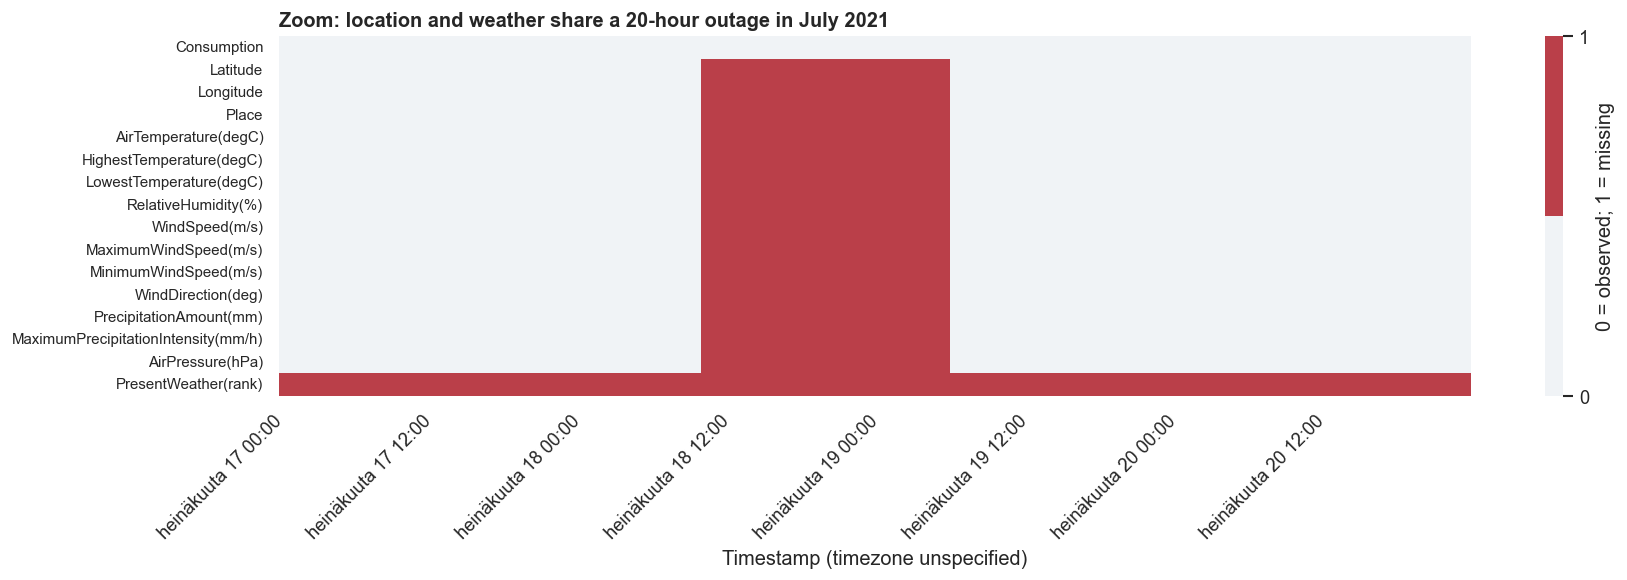

In [5]:
patterns = missing.apply(lambda row: ', '.join(row.index[row]) or 'Complete', axis=1)
pattern_table = patterns.value_counts().rename_axis('Missing features').to_frame('Hours')
pattern_table['Hours (%)'] = pattern_table['Hours'].div(len(aligned)).mul(100)
display(pattern_table.head(10).round(3))

location_cols = ['Latitude', 'Longitude', 'Place']
weather_cols = [c for c in aligned if c not in ['Consumption'] + location_cols]
location_mask = missing['Latitude']
assert all(missing[c].equals(location_mask) for c in location_cols)
print('Identical location missingness masks:', True)
print('Hours with missing location:', int(location_mask.sum()))
print('All weather columns missing at those hours:', bool(missing.loc[location_mask, weather_cols].all().all()))
print('Distinct observed location values:', aligned[location_cols].nunique().to_dict())

window = missing.loc['2021-07-17':'2021-07-20']
fig, ax = plt.subplots(figsize=(15, 5))
from matplotlib.colors import ListedColormap
sns.heatmap(window.T.astype(int), ax=ax, cmap=ListedColormap(['#f0f3f6', '#ba3f49']),
            vmin=0, vmax=1, cbar_kws={'ticks': [0, 1], 'label': '0 = observed; 1 = missing'},
            xticklabels=False, yticklabels=True)
ticks = np.arange(0, len(window), 12)
ax.set_xticks(ticks + .5)
ax.set_xticklabels(window.index[ticks].strftime('%b %d %H:%M'), rotation=45, ha='right')
ax.set_xlabel('Timestamp (timezone unspecified)')
ax.set_ylabel('')
ax.tick_params(axis='y', labelsize=9, rotation=0)
ax.set_title('Zoom: location and weather share a 20-hour outage in July 2021', loc='left', weight='bold')
fig.tight_layout()
plt.show()

**Finding:** The 191 missing location rows occur in **151 separate runs**, with a median of one hour and a maximum of 20 hours. Every one of these rows also lacks all weather fields, while consumption remains available. This is consistent with unavailable weather records or a data-merge issue, but the CSV alone cannot establish the cause. The three location fields each have only one distinct observed value.

## 6. Quantify the cost of dropping incomplete rows

Report this before recommending deletion or imputation. The calculation below is a sensitivity comparison, not a decision to remove weather rank.

In [6]:
retention = pd.DataFrame({
    'Rule': ['Require every feature', 'Require every feature except weather rank', 'Require consumption only'],
    'Retained hours': [int(aligned.notna().all(axis=1).sum()),
                       int(aligned[other_cols].notna().all(axis=1).sum()),
                       int(aligned['Consumption'].notna().sum())]
})
retention['Retained (%)'] = retention['Retained hours'].div(len(aligned)).mul(100)
display(retention.round(3))
print('Consumption zero values (observed, not treated as missing):', int(aligned['Consumption'].eq(0).sum()))

,Rule,Retained hours,Retained (%)
0,Require every feature,23654,42.066
1,Require every feature except weather rank,55282,98.312
2,Require consumption only,56231,100.000


Consumption zero values (observed, not treated as missing): 0


## How to present this EDA

Use the feature summary and percentage bars to answer **how much**, the monthly heatmap to answer **when**, and the gap table plus zoom to answer **how long and together**. Keep the complete exact-pattern table available as supporting evidence. Avoid showing only the full-resolution hourly heatmap, which squeezes 56,231 rows into a few hundred pixels.

### Suggested interpretation for a report

The dataset has a complete hourly timeline and no missing consumption values. Weather rank is the main coverage limitation, with 57.69% missing values concentrated in long blocks at the beginning and end of the record. Other variables have missingness rates from 0.34% to 1.32%, but the longest wind gaps reach 80 hours. Location information is missing at the same 191 hours across all three location columns, and these hours also lack all weather observations. Requiring every feature would retain only 23,654 hours (42.07%), whereas requiring all features except weather rank retains 55,282 hours (98.31%).

### Decide treatment after this exploration

- **Consumption:** no missing-value treatment is needed for this column under the current parsing rules. Completeness does not validate the values themselves.
- **Location metadata:** one station is observed. If source documentation confirms this station applies throughout, filling its fixed metadata may be justified. This does not recover missing weather observations.
- **Weather rank:** check its definition, reporting conventions and source coverage first. Do not assume missing codes mean clear weather or zero. Consider excluding it from a full-period model, or analyzing the period where it is observed separately, depending on the research question.
- **Continuous weather measurements:** distinguish isolated gaps from longer outages. Evaluate short-gap interpolation or external-source recovery, with limits appropriate to each variable. An 80-hour outage should not automatically receive the same treatment as a one-hour gap. Precipitation and circular wind direction require variable-specific methods.
- **Forecasting:** split training and evaluation data before fitting any learned imputation. Using later observations for interpolation can leak future information when those observations would not be available at prediction time.
- **Missingness mechanism:** temporal clustering and co-occurrence are observable evidence, but do not establish MCAR, MAR or MNAR. Compare missingness by year, season and observed consumption, while accounting for time trends and autocorrelation. Source documentation is needed to investigate the reasons for missingness.

No imputation, deletion, timezone conversion, or sentinel recoding has been applied in this notebook.